# Customer Churn Prediction
## Group 4

Fabio Augusto De Oliveira Dutra · Gumashtha Devangiri Pandukabhaya Punchi Wedikkarage Don · Jose Vidal Asencio Santos · Mehrthur Luís Lemos da Silva
## 1 Problem Definition


This study compares baseline and optimized Logistic Regression and Decision Tree classifiers for telecom customer retention. The target is Churn Value, with 1 indicating cancellation and 0 indicating retention. All four models use 19 predictors without ZIP Code. Churn F1 is the selection metric because missing churners and raising false alerts both matter.

Install requirements.txt, keep Dataset_Churn.xlsx beside this notebook, and execute the cells in order. The final cell exports the selected classifier and input schema for the local API.


In [1]:
# Import the analysis libraries, configure plot formatting, and record package versions.
# Install dependencies in the notebook environment if necessary:
# %pip install pandas numpy matplotlib seaborn scikit-learn openpyxl
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, FixedThresholdClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score,
)
import sklearn

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
import platform
import scipy
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| SciPy:", scipy.__version__)


pandas: 3.0.6 | scikit-learn: 1.9.1
Python: 3.14.8 | NumPy: 2.5.3 | SciPy: 1.18.1


## 2 Data Inspection and Feature Selection

The IBM Telco file contains 7,043 customers and 33 columns. Thirteen fields are excluded, leaving 19 predictors and the target. Identifiers, constant fields, outcome-related columns and geographic fields are removed. CLTV is excluded because its construction and availability before prediction remain unverified.

ZIP Code is removed after showing little incremental importance in an earlier training diagnostic. The controlled comparison below measures its effect at fixed LR settings. All models share the stratified 80/20 split, with 5,634 training and 1,409 test customers. Detailed exploratory analysis uses training data. [Dataset source](https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset)


In [2]:
# Load the customer file and inspect its dimensions, column types, missing values, and duplicate rows.
# Support both the repository and the supplied assignment copy.
data_candidates = [Path("Dataset_Churn.xlsx"), Path("Assignment 1 Dataset.xlsx")]
DATA_PATH = next((p for p in data_candidates if p.is_file()), data_candidates[0])
EXCEL_SHEET = 0

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. Download the dataset, "
        "place it beside this notebook, and update DATA_PATH."
    )
if DATA_PATH.suffix.lower() == ".csv":
    raw = pd.read_csv(DATA_PATH)
elif DATA_PATH.suffix.lower() in {".xlsx", ".xls"}:
    raw = pd.read_excel(DATA_PATH, sheet_name=EXCEL_SHEET)
else:
    raise ValueError("Use a CSV or Excel file; extract downloaded ZIP archives first.")
raw.columns = raw.columns.str.strip()
if raw.columns.duplicated().any():
    raise ValueError("Duplicate column names found; inspect the source file.")
print("Raw dimensions:", raw.shape)
display(raw.head())
raw.info()
display(raw.describe(include="all").T)
display(raw.isna().sum().sort_values(ascending=False).to_frame("Missing"))
print("Exact duplicate rows:", raw.duplicated().sum())


Raw dimensions: (7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,7043,7043,3668-QPYBK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
Lat Long,7043,1652,"33.964131, -118.272783",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing
Churn Reason,5174
Online Security,0
CLTV,0
Churn Score,0
Churn Value,0
Churn Label,0
Total Charges,0
Monthly Charges,0
Payment Method,0
Paperless Billing,0


In [3]:
# Validate the churn labels, clean billing values, and exclude identifiers, outcome fields, and geography.
def column_key(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

TARGET_COLUMN = "Churn Value"  # Set explicitly if automatic detection is ambiguous.
target_keys = {"churn", "churnlabel", "churnvalue"}
candidates = [c for c in raw.columns if column_key(c) in target_keys]
if TARGET_COLUMN is None:
    if len(candidates) != 1:
        raise ValueError(f"Set TARGET_COLUMN explicitly. Candidate target fields: {candidates}")
    TARGET_COLUMN = candidates[0]
if TARGET_COLUMN not in raw.columns:
    raise ValueError(f"Target not found: {TARGET_COLUMN}")

# Extend after reading the dataset dictionary and defining the prediction time.
# Remove constant fields and all geographic representations in this revision.
EXTRA_EXCLUDE = ["CLTV", "Country", "State", "City", "Lat Long", "Latitude", "Longitude", "Zip Code"]
excluded_keys = {
    "customerid", "customerstatus", "churn", "churnlabel", "churnvalue",
    "churnscore", "churncategory", "churnreason", "count",
}
excluded = [c for c in raw.columns
            if c != TARGET_COLUMN and (column_key(c) in excluded_keys or c in EXTRA_EXCLUDE)]

clean = raw.copy()
text_columns = clean.select_dtypes(include=["object", "string"]).columns
for col in text_columns:
    clean[col] = clean[col].map(lambda value: value.strip() if isinstance(value, str) else value)
clean = clean.replace(r"^\s*$", np.nan, regex=True)
for col in clean.columns:
    if column_key(col) in {"totalcharges", "monthlycharges", "monthlycharge"}:
        clean[col] = pd.to_numeric(clean[col], errors="raise")

before = len(clean)
clean = clean.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(clean))
if clean[TARGET_COLUMN].isna().any():
    raise ValueError("Missing target labels found. Investigate before proceeding.")
label_map = {"yes": 1, "no": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0}
y = clean[TARGET_COLUMN].astype(str).str.strip().str.lower().map(label_map)
if y.isna().any() or y.nunique() != 2:
    raise ValueError("Expected two target classes encoded as Yes/No or 1/0. Inspect target values.")
y = y.astype(int).rename("Churn")
X = clean.drop(columns=[TARGET_COLUMN] + excluded)
# ZIP codes identify areas; numeric distances between codes have no meaning.
for col in X.columns:
    if column_key(col) == "zipcode":
        codes = pd.to_numeric(X[col], errors="raise")
        if ((codes.dropna() % 1) != 0).any():
            raise ValueError("ZIP Code must contain integer codes or missing values.")
        X[col] = codes.map(lambda value: f"{int(value):05d}" if pd.notna(value) else np.nan)
if X.empty:
    raise ValueError("No predictors remain.")
print("Target:", TARGET_COLUMN)
print("Excluded columns:", excluded)
display(pd.DataFrame({"dtype": X.dtypes, "unique": X.nunique(), "missing": X.isna().sum()}))

id_cols = [c for c in clean.columns if column_key(c) == "customerid"]
for col in id_cols:
    if clean[col].duplicated().any():
        raise ValueError("Repeated customer IDs found. Investigate and use a customer-level split if needed.")

Exact duplicate rows removed: 0
Target: Churn Value
Excluded columns: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Reason']


,dtype,unique,missing
Gender,str,2,0
Senior Citizen,str,2,0
Partner,str,2,0
Dependents,str,2,0
Tenure Months,int64,73,0
Phone Service,str,2,0
Multiple Lines,str,3,0
Internet Service,str,3,0
Online Security,str,3,0
Online Backup,str,3,0


In [4]:
# Create the shared stratified 80/20 split and summarize the training data used for exploration.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Training dimensions:", X_train.shape)
print("Test dimensions:", X_test.shape)
eda = X_train.copy()
eda["Churn"] = y_train
class_summary = y_train.value_counts().sort_index().to_frame("Count")
class_summary["Proportion"] = y_train.value_counts(normalize=True).sort_index()
display(class_summary)
display(X_train.describe(include="all").T)
display(X_train.isna().sum().sort_values(ascending=False).to_frame("Training missing"))

Training dimensions: (5634, 19)
Test dimensions: (1409, 19)


,Count,Proportion
Churn,,
0,4139,0.734647
1,1495,0.265353


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,5634,2,Male,2833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Senior Citizen,5634,2,No,4714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Partner,5634,2,No,2905,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,5634,2,No,4333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tenure Months,5634.0,NaN,NaN,NaN,32.485091,24.568744,0.0,9.0,29.0,55.0,72.0
Phone Service,5634,2,Yes,5075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Multiple Lines,5634,3,No,2685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet Service,5634,3,Fiber optic,2483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online Security,5634,3,No,2797,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Online Backup,5634,3,No,2442,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Training missing
Total Charges,8
Device Protection,0
Monthly Charges,0
Payment Method,0
Paperless Billing,0
Contract,0
Streaming Movies,0
Streaming TV,0
Tech Support,0
Gender,0


## 3 Exploratory Data Analysis

The plots examine training class balance, tenure, contract type and numerical correlations. The following tables summarize billing differences, missing values and potential outliers.


Tenure for missing Total Charges:


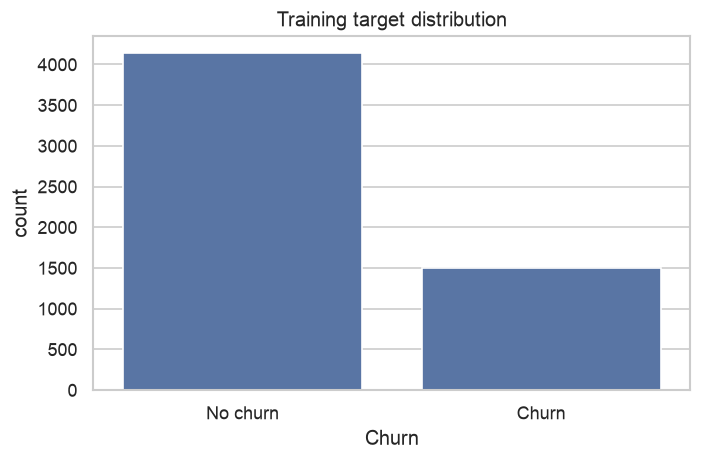

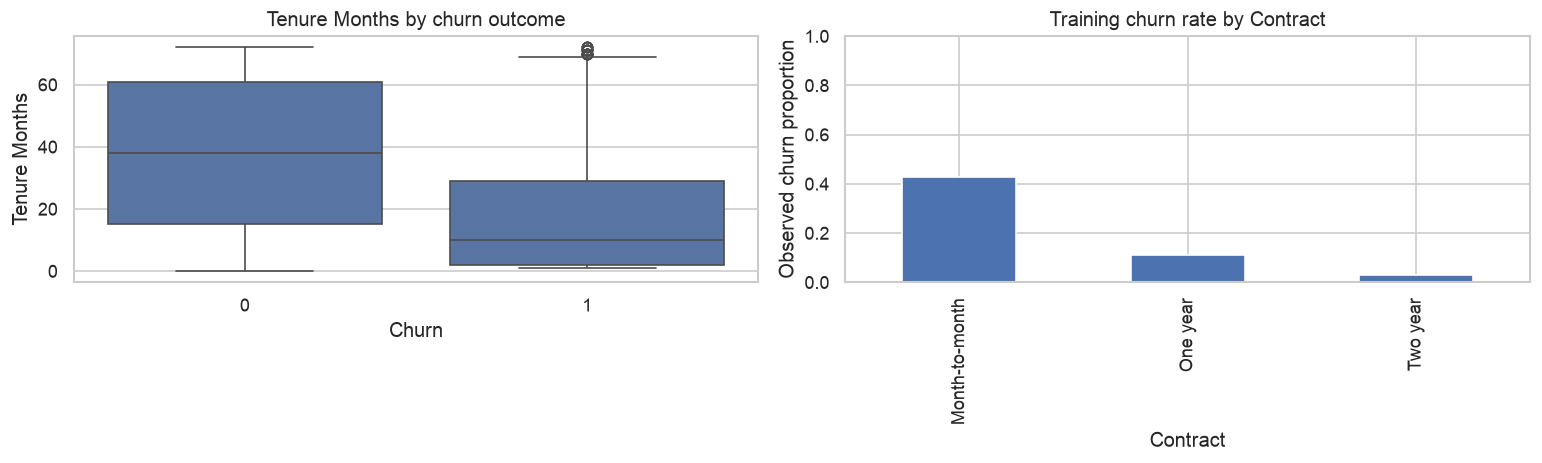

,Churn rate,Customers
Contract,,
Month-to-month,0.427466,3102
One year,0.110827,1173
Two year,0.028698,1359


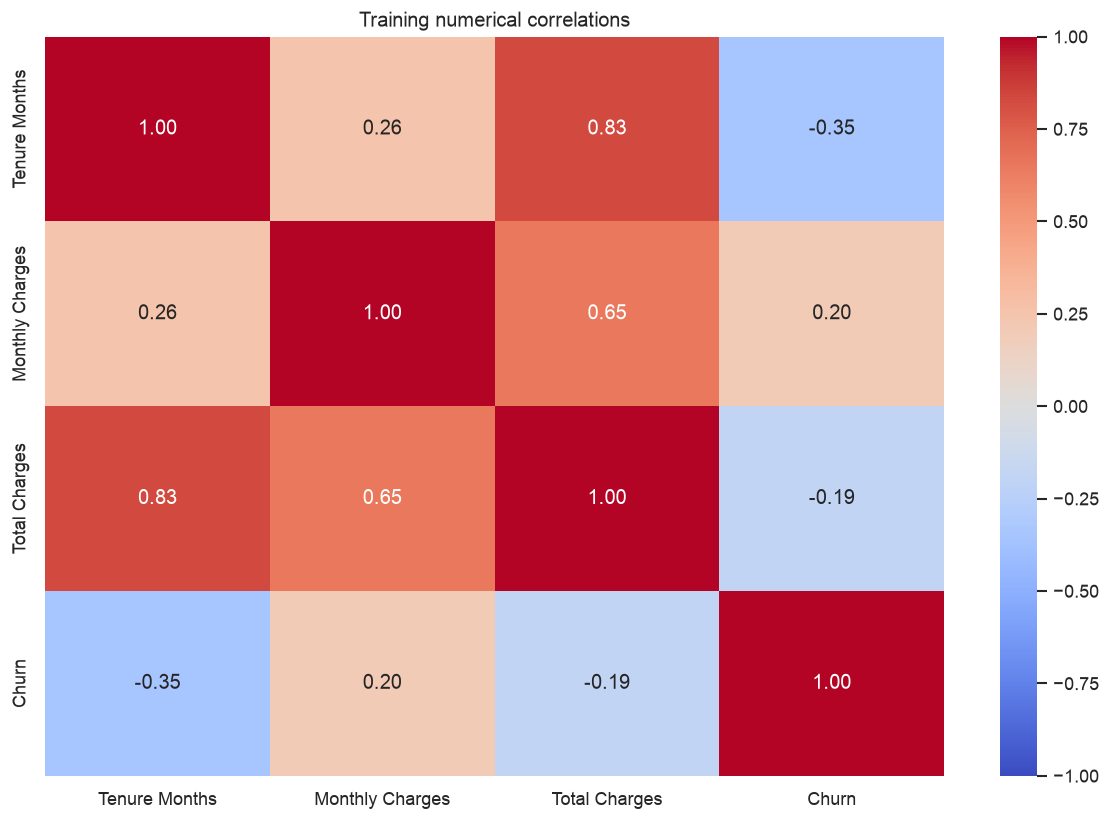

,Correlation with churn
Tenure Months,-0.345593
Total Charges,-0.194814
Monthly Charges,0.198040


,Tenure Months,Monthly Charges,Total Charges
Churn,,,
No churn,38.0,64.40,1691.9
Churn,10.0,79.95,740.3


,Outside 1.5 IQR fences
Tenure Months,0
Monthly Charges,0
Total Charges,0


Tenure Months
0    11
Name: count, dtype: int64

In [5]:
# Plot churn balance and customer relationships, then quantify correlations, missing charges, and outliers.
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=eda, x="Churn", ax=ax)
ax.set_xticks([0, 1], ["No churn", "Churn"])
ax.set_title("Training target distribution")
plt.tight_layout()
plt.show()

numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_columns = [c for c in X_train.columns if c not in numeric_columns]
# Prefer interpretable fields, with fallbacks for other dataset variants.
by_key = {column_key(c): c for c in X_train.columns}
num_plot = next((by_key[k] for k in ["tenure", "tenuremonths", "tenureinmonths", "monthlycharges", "monthlycharge"]
                 if k in by_key and by_key[k] in numeric_columns), None)
if num_plot is None and numeric_columns:
    num_plot = numeric_columns[0]
cat_plot = next((by_key[k] for k in ["contract", "internetservice", "paymentmethod"]
                 if k in by_key and by_key[k] in categorical_columns), None)
if cat_plot is None:
    cat_plot = next((c for c in categorical_columns if X_train[c].nunique() <= 15), None)
if num_plot is None or cat_plot is None:
    raise ValueError("Select suitable numerical and categorical fields for the required EDA plots.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=eda, x="Churn", y=num_plot, ax=axes[0])
axes[0].set_title(f"{num_plot} by churn outcome")
rates = eda.groupby(cat_plot, observed=True)["Churn"].agg(["mean", "size"])
rates["mean"].plot.bar(ax=axes[1])
axes[1].set_ylabel("Observed churn proportion")
axes[1].set_ylim(0, 1)
axes[1].set_title(f"Training churn rate by {cat_plot}")
plt.tight_layout()
plt.show()
display(rates.rename(columns={"mean": "Churn rate", "size": "Customers"}))

if numeric_columns:
    corr = eda[numeric_columns + ["Churn"]].corr()
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
    plt.title("Training numerical correlations")
    plt.tight_layout()
    plt.show()
# Numerical evidence for the written EDA, using training data only.
display(corr["Churn"].drop("Churn").sort_values().to_frame("Correlation with churn"))
eda_by_churn = eda.groupby("Churn")[numeric_columns].median()
display(eda_by_churn.rename(index={0: "No churn", 1: "Churn"}))
q1 = X_train[numeric_columns].quantile(0.25)
q3 = X_train[numeric_columns].quantile(0.75)
iqr = q3 - q1
outlier_counts = ((X_train[numeric_columns] < q1 - 1.5 * iqr) |
                  (X_train[numeric_columns] > q3 + 1.5 * iqr)).sum()
display(outlier_counts.to_frame("Outside 1.5 IQR fences"))
print("Tenure for missing Total Charges:")
display(clean.loc[clean["Total Charges"].isna(), "Tenure Months"].value_counts())


### Findings

Training contains 26.54% churners. Their median tenure is 10 months, compared with 38 for customers who stayed. Month-to-month contracts have 42.75% churn, versus 11.08% for one-year and 2.87% for two-year contracts. Churners have higher median monthly charges and lower median total charges.

Total Charges contains 11 missing values in the full file, including eight in training. All affected customers have zero tenure. No exact duplicate rows or numerical training values beyond the 1.5-IQR fences were found. These relationships describe associations and support evaluating contract, tenure and billing as predictors.


## 4 Data Preprocessing

Numeric inputs use training-fold median imputation and StandardScaler. The 16 categorical inputs use most-frequent imputation and one-hot encoding, with unseen categories ignored. Pipeline and ColumnTransformer fit these transformations separately within each validation fold.

The same preprocessing is applied to every classifier. Balanced class weights are considered during LR tuning.


In [6]:
# Build fold-fitted imputation, encoding, and scaling pipelines for both classifier families.
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])

def make_model(estimator):
    return Pipeline([("preprocessor", make_preprocessor()), ("model", estimator)])

all_missing = X_train.columns[X_train.isna().all()].tolist()
if all_missing:
    raise ValueError(f"Entirely missing training columns require a decision: {all_missing}")

## 5 Model Development and Selection

Five shuffled stratified folds compare churn F1. GridSearchCV evaluates eight LR configurations and 48 tree configurations. Baselines use their initial settings.

Optimized LR uses a fixed cutoff of 0.60 during CV scoring. The other three configurations use their default 0.50 rule. This cutoff follows earlier training diagnostics and was fixed before the current execution. ROC-AUC uses probability scores.


In [7]:
# Evaluate baseline models with five-fold CV and define scoring at the optimized LR cutoff of 0.60.
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
SELECTION_METRIC = "f1"
if y_train.value_counts().min() < CV.n_splits:
    raise ValueError("Not enough minority-class observations for five-fold stratified CV.")

baseline_models = {
    "Logistic Regression (Baseline)": make_model(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    "Decision Tree (Baseline)": make_model(
        DecisionTreeClassifier(random_state=RANDOM_STATE)),
}
cv_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    row = {"Model": name}
    for metric in SCORING:
        row[f"CV {metric} mean"] = scores[f"test_{metric}"].mean()
        row[f"CV {metric} std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)
    model.fit(X_train, y_train)
display(pd.DataFrame(cv_rows).set_index("Model").round(4))
# Apply the requested cutoff consistently in CV scoring, evaluation and export.
LR_THRESHOLD = 0.60
def predict_at_threshold(estimator, features, threshold):
    if threshold == 0.50:
        return estimator.predict(features)
    probabilities = estimator.predict_proba(features)[:, list(estimator.classes_).index(1)]
    return (probabilities >= threshold).astype(int)

def threshold_accuracy(estimator, features, target):
    return accuracy_score(target, predict_at_threshold(estimator, features, LR_THRESHOLD))
def threshold_precision(estimator, features, target):
    return precision_score(target, predict_at_threshold(estimator, features, LR_THRESHOLD), zero_division=0)
def threshold_recall(estimator, features, target):
    return recall_score(target, predict_at_threshold(estimator, features, LR_THRESHOLD), zero_division=0)
def threshold_f1(estimator, features, target):
    return f1_score(target, predict_at_threshold(estimator, features, LR_THRESHOLD), zero_division=0)
LR_SCORING = {"accuracy": threshold_accuracy, "precision": threshold_precision,
              "recall": threshold_recall, "f1": threshold_f1, "roc_auc": "roc_auc"}


,CV accuracy mean,CV accuracy std,CV precision mean,CV precision std,CV recall mean,CV recall std,CV f1 mean,CV f1 std,CV roc_auc mean,CV roc_auc std
Model,,,,,,,,,,
Logistic Regression (Baseline),0.8117,0.0115,0.6663,0.0236,0.5819,0.0421,0.6206,0.0291,0.8589,0.0126
Decision Tree (Baseline),0.7364,0.0111,0.5027,0.0212,0.5050,0.0474,0.5033,0.0324,0.6626,0.0226


In [8]:
# Search LR and tree hyperparameters, compare training CV F1, and select the candidate configuration.
search_specs = {
    "Optimized Logistic Regression": (
        make_model(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
        {"model__C": [0.01, 0.1, 1.0, 10.0],
         "model__class_weight": [None, "balanced"]},
    ),
    "Optimized Decision Tree": (
        make_model(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {"model__max_depth": [3, 5, 8, None],
         "model__min_samples_leaf": [1, 5, 15],
         "model__min_samples_split": [2, 10],
         "model__criterion": ["gini", "entropy"]},
    ),
}
searches = {}
for name, (pipeline, param_grid) in search_specs.items():
    search = GridSearchCV(
        pipeline, param_grid, cv=CV, scoring=LR_SCORING if name == "Optimized Logistic Regression" else SCORING,
        refit=SELECTION_METRIC, n_jobs=-1, error_score="raise",
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(name)
    print("Best parameters:", search.best_params_)
    print("Best cross-validation F1:", round(search.best_score_, 4))
    results = pd.DataFrame(search.cv_results_)
    display(results[["params", "mean_test_f1", "std_test_f1", "mean_test_recall",
                     "mean_test_precision"]].sort_values("mean_test_f1", ascending=False).head())

models = {**baseline_models, **{name: search.best_estimator_ for name, search in searches.items()}}
selection_rows = [{"Model": row["Model"], "CV F1": row["CV f1 mean"]} for row in cv_rows]
selection_rows += [{"Model": name, "CV F1": search.best_score_} for name, search in searches.items()]
selection_table = pd.DataFrame(selection_rows).set_index("Model").sort_values("CV F1", ascending=False)
recommended_name = selection_table.index[0]
display(selection_table)
print("Model selected using training CV only:", recommended_name)

optimization_summary = [{"Model": row["Model"], "Mean CV F1": row["CV f1 mean"],
    "Fold SD": row["CV f1 std"], "Settings": "Initial untuned configuration"} for row in cv_rows]
for name, search in searches.items():
    optimization_summary.append({"Model": name, "Mean CV F1": search.best_score_,
        "Fold SD": search.cv_results_["std_test_f1"][search.best_index_],
        "Settings": str(search.best_params_)})
display(pd.DataFrame(optimization_summary).set_index("Model").round(4))


Optimized Logistic Regression
Best parameters: {'model__C': 0.01, 'model__class_weight': 'balanced'}
Best cross-validation F1: 0.6512
Optimized Decision Tree
Best parameters: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_leaf': 15, 'model__min_samples_split': 2}
Best cross-validation F1: 0.6128
Model selected using training CV only: Optimized Logistic Regression


,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision
1,"{'model__C': 0.01, 'model__class_weight': 'bal...",0.651166,0.021118,0.717726,0.596546
5,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.651137,0.026568,0.733779,0.585782
3,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.650755,0.022242,0.732441,0.585996
7,"{'model__C': 10.0, 'model__class_weight': 'bal...",0.648691,0.028224,0.731773,0.582993
4,"{'model__C': 1.0, 'model__class_weight': None}",0.548564,0.021778,0.441472,0.725989


,params,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision
35,"{'model__criterion': 'entropy', 'model__max_de...",0.612828,0.028970,0.616722,0.615253
34,"{'model__criterion': 'entropy', 'model__max_de...",0.612828,0.028970,0.616722,0.615253
33,"{'model__criterion': 'entropy', 'model__max_de...",0.612416,0.028457,0.616054,0.615027
32,"{'model__criterion': 'entropy', 'model__max_de...",0.612416,0.028457,0.616054,0.615027
31,"{'model__criterion': 'entropy', 'model__max_de...",0.611209,0.028223,0.614716,0.614003


,CV F1
Model,
Optimized Logistic Regression,0.651166
Logistic Regression (Baseline),0.620606
Optimized Decision Tree,0.612828
Decision Tree (Baseline),0.503286


,Mean CV F1,Fold SD,Settings
Model,,,
Logistic Regression (Baseline),0.6206,0.0291,Initial untuned configuration
Decision Tree (Baseline),0.5033,0.0324,Initial untuned configuration
Optimized Logistic Regression,0.6512,0.0211,"{'model__C': 0.01, 'model__class_weight': 'bal..."
Optimized Decision Tree,0.6128,0.0290,"{'model__criterion': 'entropy', 'model__max_de..."


## 6 Model Evaluation

All four fitted models are evaluated on the same 1,409 test customers. Precision, recall and F1 refer to churn. The comparison includes confusion matrices, ranking metrics, error costs and conditional bootstrap intervals.

The test split was inspected during earlier development. These results remain exploratory. Bootstrap resampling conditions on the fitted models, and out-of-fold calibration and threshold diagnostics follow hyperparameter selection. Independent data is needed to confirm performance.



Logistic Regression (Baseline)
              precision    recall  f1-score   support

    No churn     0.8506    0.8860    0.8680      1035
       Churn     0.6435    0.5695    0.6043       374

    accuracy                         0.8020      1409
   macro avg     0.7471    0.7278    0.7361      1409
weighted avg     0.7957    0.8020    0.7980      1409


Decision Tree (Baseline)
              precision    recall  f1-score   support

    No churn     0.8370    0.8087    0.8226      1035
       Churn     0.5159    0.5642    0.5390       374

    accuracy                         0.7438      1409
   macro avg     0.6764    0.6864    0.6808      1409
weighted avg     0.7518    0.7438    0.7473      1409


Optimized Logistic Regression
              precision    recall  f1-score   support

    No churn     0.8825    0.8058    0.8424      1035
       Churn     0.5668    0.7032    0.6277       374

    accuracy                         0.7786      1409
   macro avg     0.7247    0.7545    0.

,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,Comments
Model,,,,,,
Logistic Regression (Baseline),0.8140,0.8020,0.6435,0.5695,0.6043,Baseline; cutoff 0.50
Decision Tree (Baseline),0.9980,0.7438,0.5159,0.5642,0.5390,Unrestricted tree; cutoff 0.50
Optimized Logistic Regression,0.7985,0.7786,0.5668,0.7032,0.6277,Tuned LR; cutoff 0.60
Optimized Decision Tree,0.8032,0.7913,0.6081,0.6016,0.6048,Tuned tree; cutoff 0.50


,ROC-AUC,Average Precision,Accuracy Gap,TP,FN,FP,TN,Flagged Customers
Model,,,,,,,,
Logistic Regression (Baseline),0.8487,0.6450,0.0120,213,161,118,917,331
Decision Tree (Baseline),0.6873,0.4074,0.2543,211,163,198,837,409
Optimized Logistic Regression,0.8470,0.6418,0.0200,263,111,201,834,464
Optimized Decision Tree,0.8354,0.6155,0.0118,225,149,145,890,370


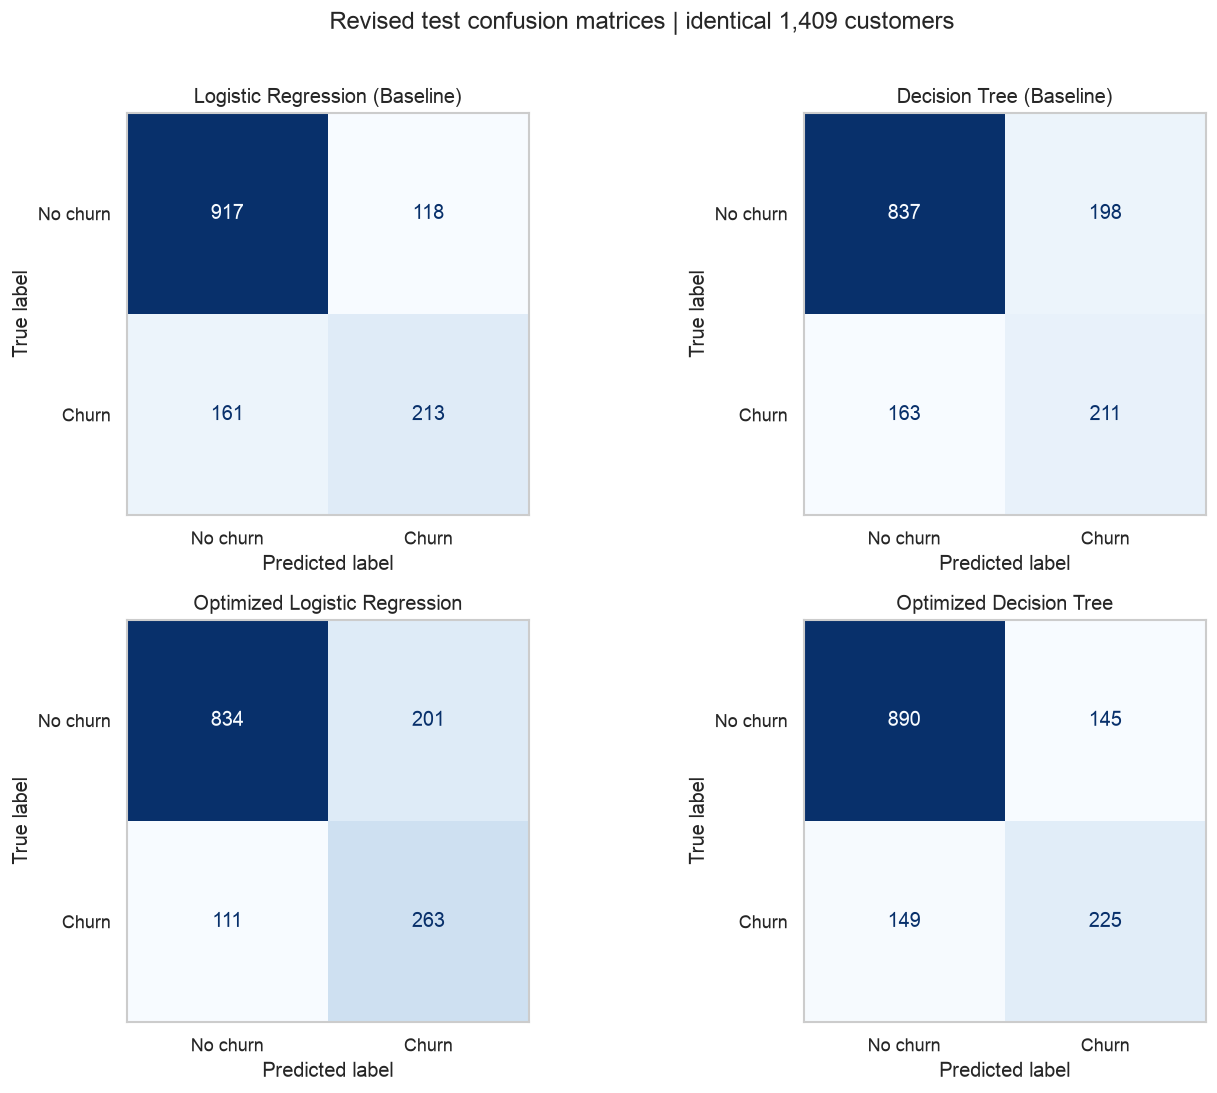

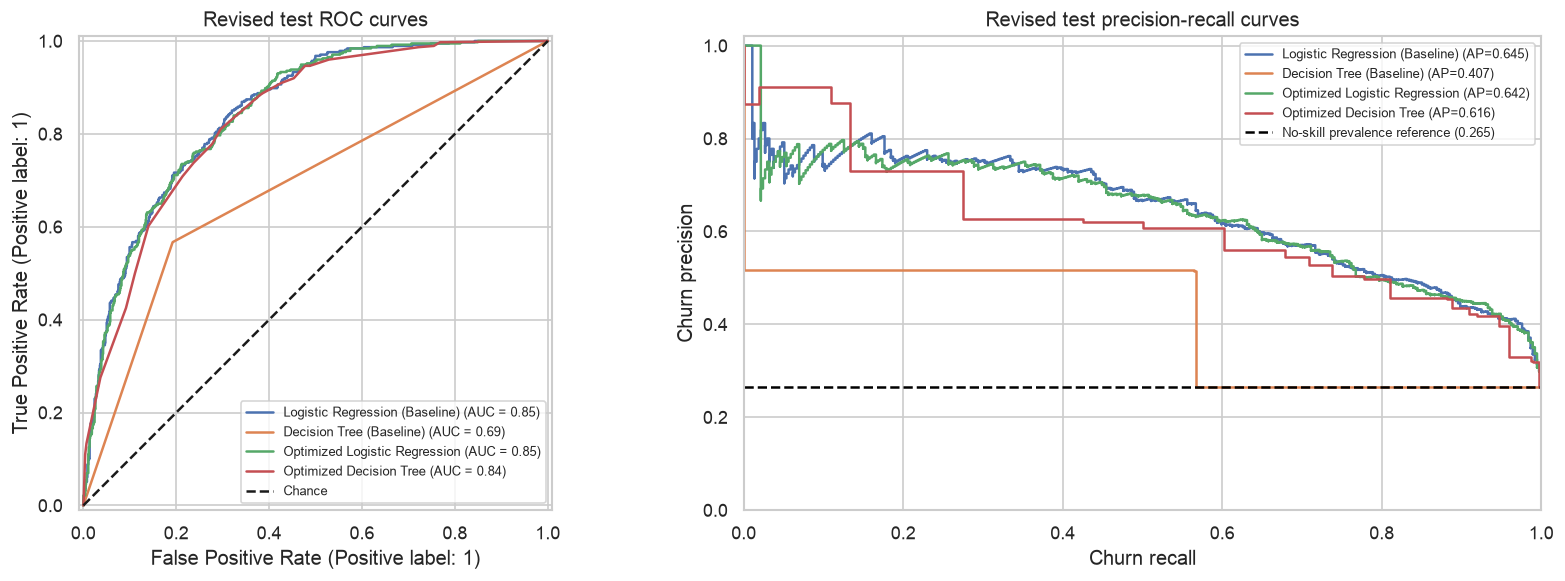

,Accuracy change (percentage points),Precision change (percentage points),Recall change (percentage points),F1 change (absolute)
Algorithm,,,,
Logistic Regression,-2.3421,-7.6694,13.3690,0.0234
Decision Tree,4.7551,9.2216,3.7433,0.0659


In [9]:
# Apply each model's cutoff and compute test metrics, confusion matrices, and ranking curves.
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix

# Every metric uses the same customers and the same fitted pipelines.
# Positive-class metrics explicitly use Churn = 1; optimized LR uses 0.60 and the other configurations use 0.50.
evaluation_rows, test_predictions, test_probabilities = [], {}, {}
for name, model in models.items():
    threshold = LR_THRESHOLD if name == "Optimized Logistic Regression" else 0.50
    train_pred = predict_at_threshold(model, X_train, threshold)
    pred = predict_at_threshold(model, X_test, threshold)
    prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    test_predictions[name], test_probabilities[name] = pred, prob
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    evaluation_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Average Precision": average_precision_score(y_test, prob),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "Flagged Customers": int(tp + fp),
    })
    print("\n" + name)
    print(classification_report(y_test, pred, labels=[0, 1],
          target_names=["No churn", "Churn"], digits=4, zero_division=0))
comparison = pd.DataFrame(evaluation_rows).set_index("Model")
comparison["Accuracy Gap"] = comparison["Train Accuracy"] - comparison["Test Accuracy"]
comparison["Comments"] = ["Baseline; cutoff 0.50", "Unrestricted tree; cutoff 0.50", "Tuned LR; cutoff 0.60", "Tuned tree; cutoff 0.50"]
display(comparison[["Train Accuracy", "Test Accuracy", "Precision", "Recall", "F1-score", "Comments"]].round(4))
print("Precision, recall and F1 refer to Churn = 1. Accuracy includes both classes.")
print("Train accuracy is resubstitution accuracy, not out-of-fold accuracy.")
display(comparison[["ROC-AUC", "Average Precision", "Accuracy Gap", "TP", "FN", "FP", "TN", "Flagged Customers"]].round(4))

# A non-learning reference contextualizes accuracy under class imbalance.
majority_pred = np.full(len(y_test), y_train.mode().iloc[0], dtype=int)
print(f"Always-no-churn reference: accuracy={accuracy_score(y_test, majority_pred):.4f}, "
      f"churn recall={recall_score(y_test, majority_pred, zero_division=0):.4f}, "
      f"churn F1={f1_score(y_test, majority_pred, zero_division=0):.4f}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, pred) in zip(axes.ravel(), test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=["No churn", "Churn"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
fig.suptitle("Revised test confusion matrices | identical 1,409 customers", y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    pr_precision, pr_recall, _ = precision_recall_curve(y_test, prob)
    axes[1].step(pr_recall, pr_precision, where="post",
                 label=f"{name} (AP={average_precision_score(y_test, prob):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].set_title("Revised test ROC curves")
axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="black", linestyle="--",
               label=f"No-skill prevalence reference ({y_test.mean():.3f})")
axes[1].set(xlabel="Churn recall", ylabel="Churn precision", xlim=(0, 1), ylim=(0, 1.02),
            title="Revised test precision-recall curves")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

change_rows = []
for algorithm, baseline, optimized in [
    ("Logistic Regression", "Logistic Regression (Baseline)", "Optimized Logistic Regression"),
    ("Decision Tree", "Decision Tree (Baseline)", "Optimized Decision Tree"),
]:
    delta = comparison.loc[optimized]  # Numeric columns selected individually below.
    change_rows.append({"Algorithm": algorithm,
        "Accuracy change (percentage points)": 100 * (delta["Test Accuracy"] - comparison.loc[baseline, "Test Accuracy"]),
        "Precision change (percentage points)": 100 * (delta["Precision"] - comparison.loc[baseline, "Precision"]),
        "Recall change (percentage points)": 100 * (delta["Recall"] - comparison.loc[baseline, "Recall"]),
        "F1 change (absolute)": delta["F1-score"] - comparison.loc[baseline, "F1-score"],
    })
display(pd.DataFrame(change_rows).set_index("Algorithm").round(4))


In [10]:
# Estimate conditional F1 uncertainty with 2,000 paired bootstrap samples and compare hypothetical error costs.
# NumPy counting keeps the 2,000 paired bootstrap repetitions fast and transparent.
rng = np.random.default_rng(RANDOM_STATE)
y_array = y_test.to_numpy()
groups = [np.flatnonzero(y_array == label) for label in (0, 1)]
names = list(test_predictions)
bootstrap_f1 = {name: np.empty(2000) for name in names}
for b in range(2000):
    idx = np.concatenate([rng.choice(g, size=len(g), replace=True) for g in groups])
    truth = y_array[idx]
    for name in names:
        pred = np.asarray(test_predictions[name])[idx]
        tp = np.count_nonzero((truth == 1) & (pred == 1))
        fp = np.count_nonzero((truth == 0) & (pred == 1))
        fn = np.count_nonzero((truth == 1) & (pred == 0))
        bootstrap_f1[name][b] = 2 * tp / (2 * tp + fp + fn)
intervals = pd.DataFrame([
    {"Model": name, "Observed F1": comparison.loc[name, "F1-score"],
     "Conditional 95% lower": np.quantile(values, .025),
     "Conditional 95% upper": np.quantile(values, .975)}
    for name, values in bootstrap_f1.items()
]).set_index("Model")
display(intervals.round(4))
f1_differences = bootstrap_f1["Optimized Logistic Regression"] - bootstrap_f1["Optimized Decision Tree"]
paired_interval = np.quantile(f1_differences, [.025, .975])
observed_difference = comparison.loc["Optimized Logistic Regression", "F1-score"] - comparison.loc["Optimized Decision Tree", "F1-score"]
print(f"Optimized LR minus optimized tree: F1 difference={observed_difference:.4f}; "
      f"conditional paired 95% interval=[{paired_interval[0]:.4f}, {paired_interval[1]:.4f}].")
print("The interval includes zero." if paired_interval[0] <= 0 <= paired_interval[1]
      else "The interval excludes zero conditional on this reused test sample and fixed models.")
print("These exploratory intervals are not independent confirmation of superiority.")

cost_rows = []
for ratio in [1, 2, 5, 10]:
    cost_rows.append({"Missed-churn / false-alert cost ratio": ratio,
        **{name: int(comparison.loc[name, "FN"] * ratio + comparison.loc[name, "FP"])
           for name in names}})
display(pd.DataFrame(cost_rows).set_index("Missed-churn / false-alert cost ratio"))
lr_row, tree_row = comparison.loc["Optimized Logistic Regression"], comparison.loc["Optimized Decision Tree"]
additional_alerts = int(lr_row["FP"] - tree_row["FP"])
additional_detected = int(tree_row["FN"] - lr_row["FN"])
print(f"Optimized LR versus optimized tree: {additional_detected} more detected churners, "
      f"{additional_alerts} more false alerts.")
if additional_detected > 0 and additional_alerts > 0:
    print(f"Their simplified error costs are equal at a missed-churn/false-alert cost ratio of "
          f"{additional_alerts / additional_detected:.2f}; above it LR has lower modeled error cost for this pair.")


Optimized LR minus optimized tree: F1 difference=0.0228; conditional paired 95% interval=[-0.0050, 0.0512].
The interval includes zero.
These exploratory intervals are not independent confirmation of superiority.
Optimized LR versus optimized tree: 38 more detected churners, 56 more false alerts.
Their simplified error costs are equal at a missed-churn/false-alert cost ratio of 1.47; above it LR has lower modeled error cost for this pair.


,Observed F1,Conditional 95% lower,Conditional 95% upper
Model,,,
Logistic Regression (Baseline),0.6043,0.5619,0.6442
Decision Tree (Baseline),0.5390,0.5000,0.5769
Optimized Logistic Regression,0.6277,0.5941,0.6604
Optimized Decision Tree,0.6048,0.5645,0.6434


,Logistic Regression (Baseline),Decision Tree (Baseline),Optimized Logistic Regression,Optimized Decision Tree
Missed-churn / false-alert cost ratio,,,,
1,279,361,312,294
2,440,524,423,443
5,923,1013,756,890
10,1728,1828,1311,1635


Constant training-prevalence Brier reference: 0.1949
Class weighting changes the fitted objective: balanced-LR probabilities should not automatically be interpreted as calibrated population churn risks. Brier loss reflects calibration and discrimination.


,OOF Brier loss,Mean predicted churn,Observed churn
Model,,,
Optimized Logistic Regression,0.1586,0.4162,0.2654
Optimized Decision Tree,0.1365,0.2647,0.2654


Precision  Recall      F1  \
Model                         Threshold                              
Optimized Logistic Regression 0.3           0.4284  0.9298  0.5865   
                              0.4           0.4862  0.8716  0.6242   
                              0.5           0.5330  0.7940  0.6378   
                              0.6           0.5964  0.7177  0.6515   
                              0.7           0.6580  0.5779  0.6154   
Optimized Decision Tree       0.3           0.5285  0.7940  0.6346   
                              0.4           0.5949  0.6582  0.6250   
                              0.5           0.6114  0.6167  0.6141   
                              0.6           0.7335  0.2742  0.3992   
                              0.7           0.7335  0.2742  0.3992   

                                         Flagged share  
Model                         Threshold                 
Optimized Logistic Regression 0.3               0.5760  
                              0.4               0.4757  
                              0.5               0.3953  
                              0.6               0.3193  
                              0.7               0.2330  
Optimized Decision Tree       0.3               0.3987  
                              0.4               0.2936  
                              0.5               0.2677  
                              0.6               0.0992  
                              0.7               0.0992

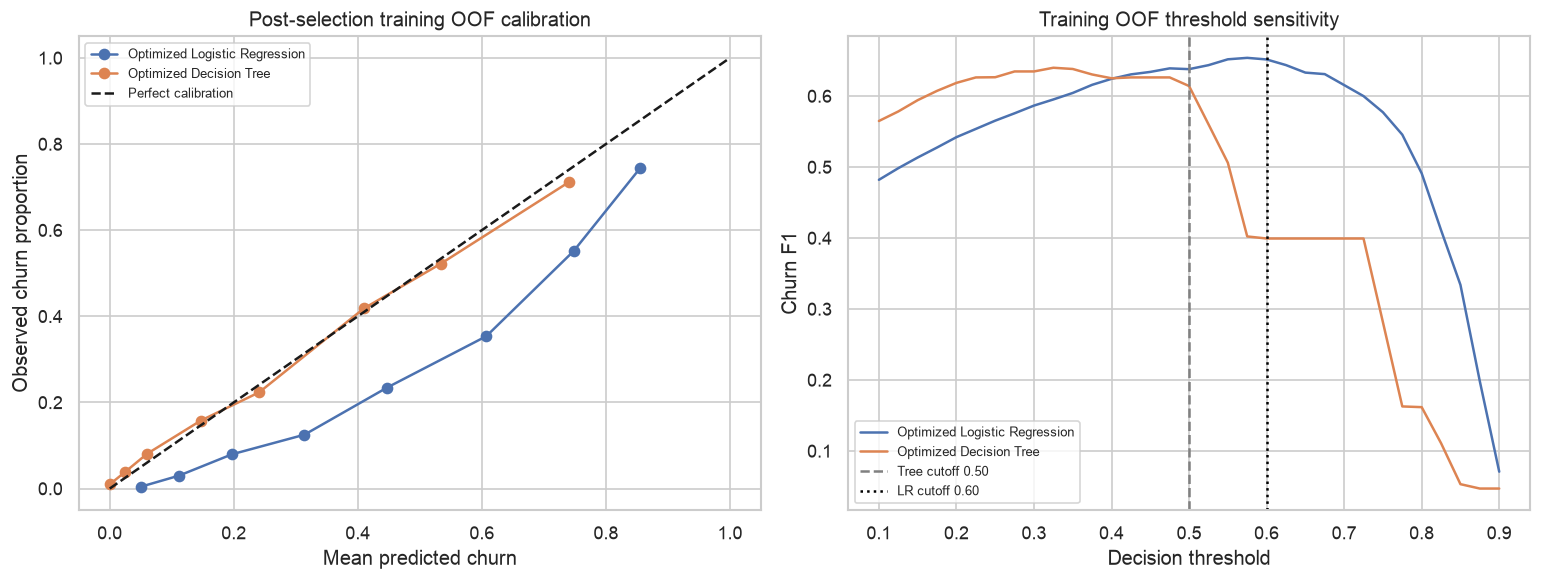


### What the probability and threshold diagnostics mean

Optimized LR's mean out-of-fold predicted churn is **41.6%**, versus an observed **26.5%**. The optimized tree's mean is **26.5%**. The reliability plot checks more than this overall average: a matching mean alone does not establish calibration across risk groups. LR's upward overall shift is consistent with the changed class-weighting objective; it should not be interpreted as evidence that 40% of customers will actually churn.

The threshold table shows that changing the cutoff can materially alter recall, precision and contact volume without retraining the model. These are pooled OOF metrics, which need not equal the unweighted mean of fold metrics in the search table. The curves are post-selection training diagnostics, so an apparent best cutoff needs separate validation. The revised test comparison and export use the fixed LR cutoff of 0.60; the other configurations use 0.50. Better F1 is not the same as better probability calibration.


In [11]:
# Generate training out-of-fold probabilities to assess calibration and cutoff sensitivity.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

oof_probabilities = {}
threshold_rows, calibration_rows = [], []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in ["Optimized Logistic Regression", "Optimized Decision Tree"]:
    model = models[name]
    oof = cross_val_predict(model, X_train, y_train, cv=CV,
                           method="predict_proba", n_jobs=1)[:, list(model.classes_).index(1)]
    oof_probabilities[name] = oof
    calibration_rows.append({"Model": name, "OOF Brier loss": brier_score_loss(y_train, oof),
                             "Mean predicted churn": oof.mean(), "Observed churn": y_train.mean()})
    observed, predicted = calibration_curve(y_train, oof, n_bins=8, strategy="quantile")
    axes[0].plot(predicted, observed, "o-", label=name)
    for threshold in [.30, .40, .50, .60, .70]:
        pred = (oof >= threshold).astype(int)
        threshold_rows.append({"Model": name, "Threshold": threshold,
            "Precision": precision_score(y_train, pred, zero_division=0),
            "Recall": recall_score(y_train, pred, zero_division=0),
            "F1": f1_score(y_train, pred, zero_division=0), "Flagged share": pred.mean()})
    thresholds = np.linspace(.1, .9, 33)
    axes[1].plot(thresholds, [f1_score(y_train, oof >= t, zero_division=0) for t in thresholds], label=name)
display(pd.DataFrame(calibration_rows).set_index("Model").round(4))
print(f"Constant training-prevalence Brier reference: {brier_score_loss(y_train, np.full(len(y_train), y_train.mean())):.4f}")
display(pd.DataFrame(threshold_rows).set_index(["Model", "Threshold"]).round(4))
axes[0].plot([0, 1], [0, 1], "k--", label="Perfect calibration")
axes[0].set(xlabel="Mean predicted churn", ylabel="Observed churn proportion", title="Post-selection training OOF calibration")
axes[1].axvline(.5, color="gray", linestyle="--", label="Tree cutoff 0.50")
axes[1].axvline(LR_THRESHOLD, color="black", linestyle=":", label="LR cutoff 0.60")
axes[1].set(xlabel="Decision threshold", ylabel="Churn F1", title="Training OOF threshold sensitivity")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Class weighting changes the fitted objective: balanced-LR probabilities should not automatically "
      "be interpreted as calibrated population churn risks. Brier loss reflects calibration and discrimination.")


from IPython.display import Markdown
calibration_table = pd.DataFrame(calibration_rows).set_index("Model")
lr_mean = calibration_table.loc["Optimized Logistic Regression", "Mean predicted churn"]
tree_mean = calibration_table.loc["Optimized Decision Tree", "Mean predicted churn"]
threshold_table = pd.DataFrame(threshold_rows)
display(Markdown(f"""
### What the probability and threshold diagnostics mean

Optimized LR's mean out-of-fold predicted churn is **{lr_mean:.1%}**, versus an observed **{y_train.mean():.1%}**. The optimized tree's mean is **{tree_mean:.1%}**. The reliability plot checks more than this overall average: a matching mean alone does not establish calibration across risk groups. LR's upward overall shift is consistent with the changed class-weighting objective; it should not be interpreted as evidence that 40% of customers will actually churn.

The threshold table shows that changing the cutoff can materially alter recall, precision and contact volume without retraining the model. These are pooled OOF metrics, which need not equal the unweighted mean of fold metrics in the search table. The curves are post-selection training diagnostics, so an apparent best cutoff needs separate validation. The revised test comparison and export use the fixed LR cutoff of 0.60; the other configurations use 0.50. Better F1 is not the same as better probability calibration.
"""))


## 7 Model Interpretation

LR coefficients describe conditional changes in log-odds. Numeric coefficients use standardized inputs, and categorical comparisons use differences between coefficients. Tree rules, impurity importance and raw-field permutation importance provide complementary views of predictive reliance.

Permutation diagnostics refit on part of the training data and score held-out training observations using the corresponding model cutoff. Correlated inputs and sample variation can change rankings. The results describe associations.


Largest absolute encoded coefficients; do not compare numeric and categorical magnitudes directly:
These conditional, regularized associations have no causal interpretation or coefficient uncertainty intervals.
Fitted tree depth: 5 | leaves: 25
Optimized Logistic Regression | diagnostic validation F1: 0.6438
Optimized Decision Tree | diagnostic validation F1: 0.5878
A raw column is shuffled before pipeline encoding, so all its one-hot levels are assessed together. Error bars show permutation-repeat SD, not confidence intervals. Correlated inputs can substitute for one another; shuffling can create unrealistic combinations. These are refitted diagnostic models.


,Coefficient
numeric__Tenure Months,-0.6146
categorical__Dependents_Yes,-0.5180
categorical__Dependents_No,0.5174
categorical__Contract_Month-to-month,0.4957
categorical__Contract_Two year,-0.3707
categorical__Internet Service_Fiber optic,0.2924
categorical__Payment Method_Electronic check,0.2578
numeric__Monthly Charges,0.2464
categorical__Internet Service_DSL,-0.2282
categorical__Online Security_No,0.2273


,Training scale (one SD),Log-odds per SD,Odds multiplier per SD
Input,,,
Tenure Months,24.5666,-0.6146,0.5409
Monthly Charges,30.1354,0.2464,1.2793
Total Charges,2277.6067,-0.1007,0.9042


,Log-odds contrast,Model-implied odds ratio
Comparison holding other inputs fixed,,
Contract: Month-to-month versus Two year,0.8664,2.3784
Contract: Month-to-month versus One year,0.6213,1.8614
Dependents: Yes versus No,-1.0354,0.3551
Internet Service: Fiber optic versus DSL,0.5206,1.6830


,Impurity importance
categorical__Contract_Month-to-month,0.5014
numeric__Tenure Months,0.1286
categorical__Internet Service_Fiber optic,0.1155
categorical__Dependents_Yes,0.1129
numeric__Monthly Charges,0.0562
categorical__Payment Method_Electronic check,0.0203
numeric__Total Charges,0.0185
categorical__Online Security_No,0.0152
categorical__Tech Support_No,0.0150
categorical__Online Backup_No,0.0077


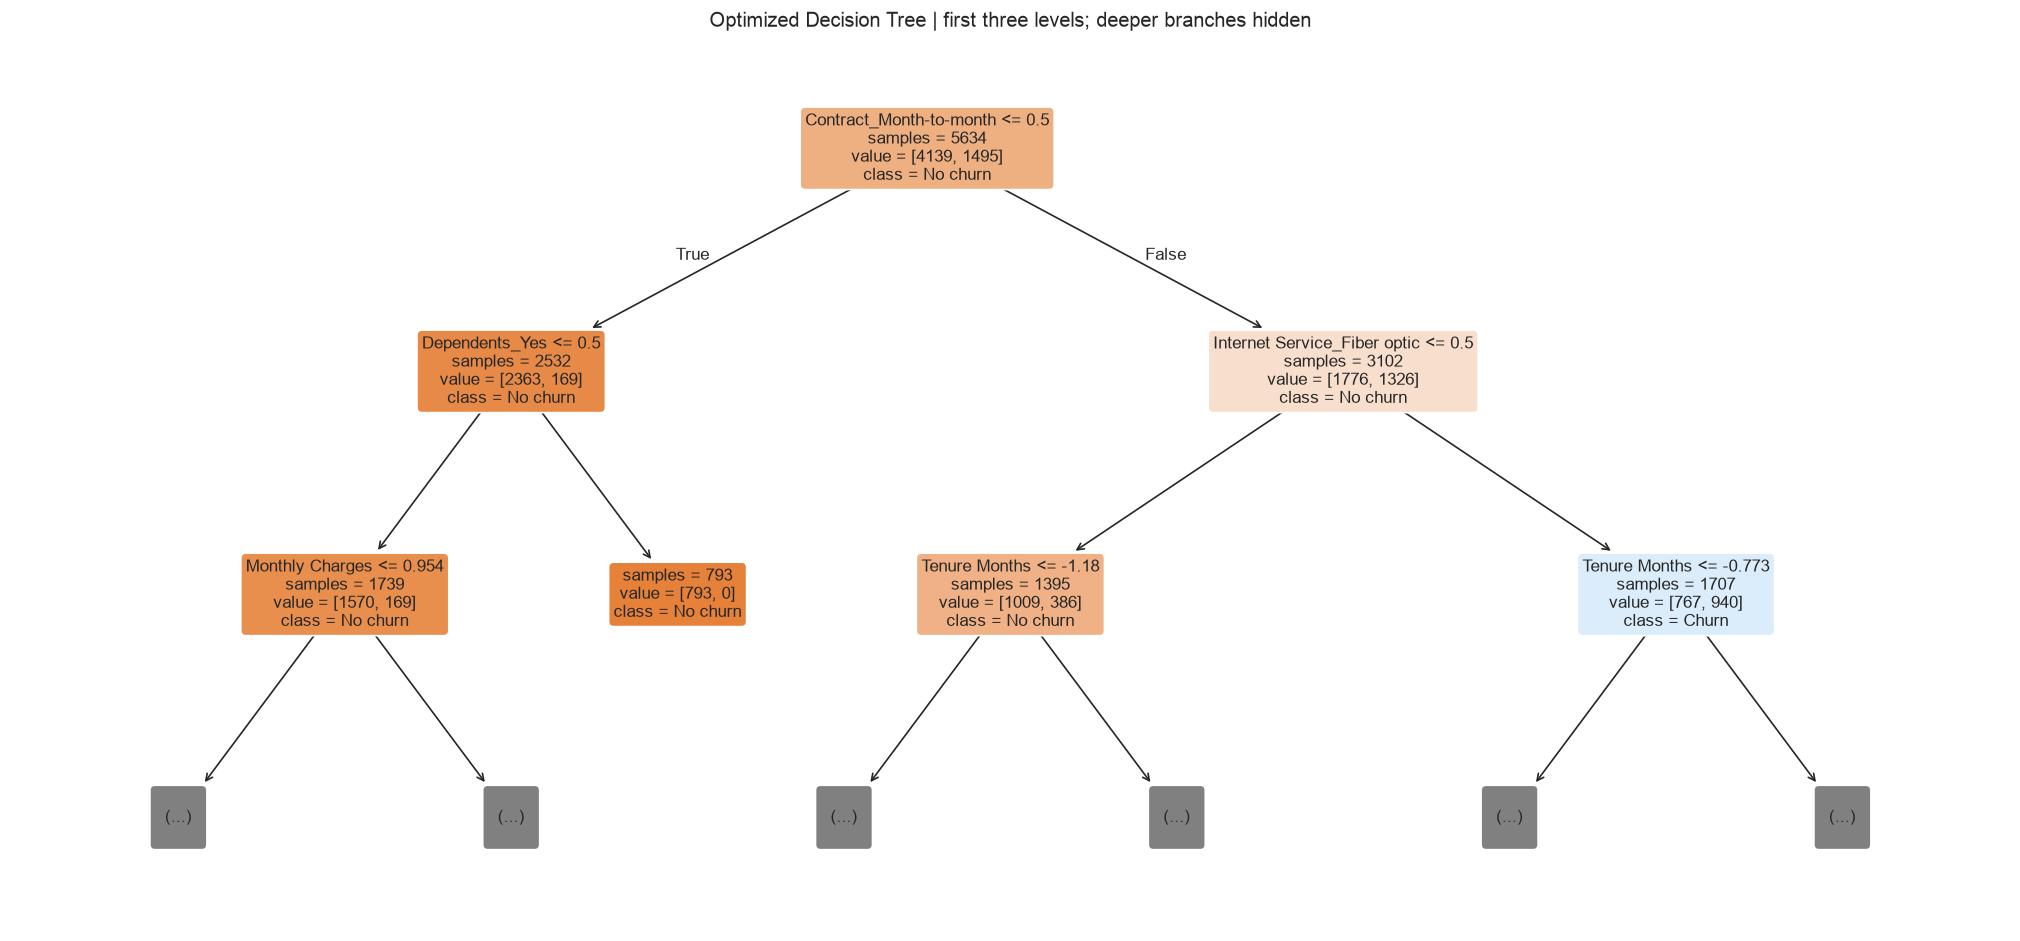

,Mean F1 decrease,Permutation SD
Tenure Months,0.0962,0.0175
Contract,0.0373,0.0079
Dependents,0.0356,0.0106
Monthly Charges,0.0180,0.0052
Internet Service,0.0173,0.0039
Paperless Billing,0.0121,0.0047
Payment Method,0.0114,0.0071
Tech Support,0.0113,0.0064
Online Security,0.0090,0.0053
Streaming TV,0.0066,0.0048


,Mean F1 decrease,Permutation SD
Contract,0.1831,0.0258
Online Security,0.1506,0.0235
Dependents,0.0788,0.0096
Internet Service,0.0536,0.0135
Total Charges,0.0269,0.0081
Tech Support,0.0000,0.0000
Monthly Charges,0.0000,0.0000
Payment Method,0.0000,0.0000
Paperless Billing,0.0000,0.0000
Streaming Movies,0.0000,0.0000


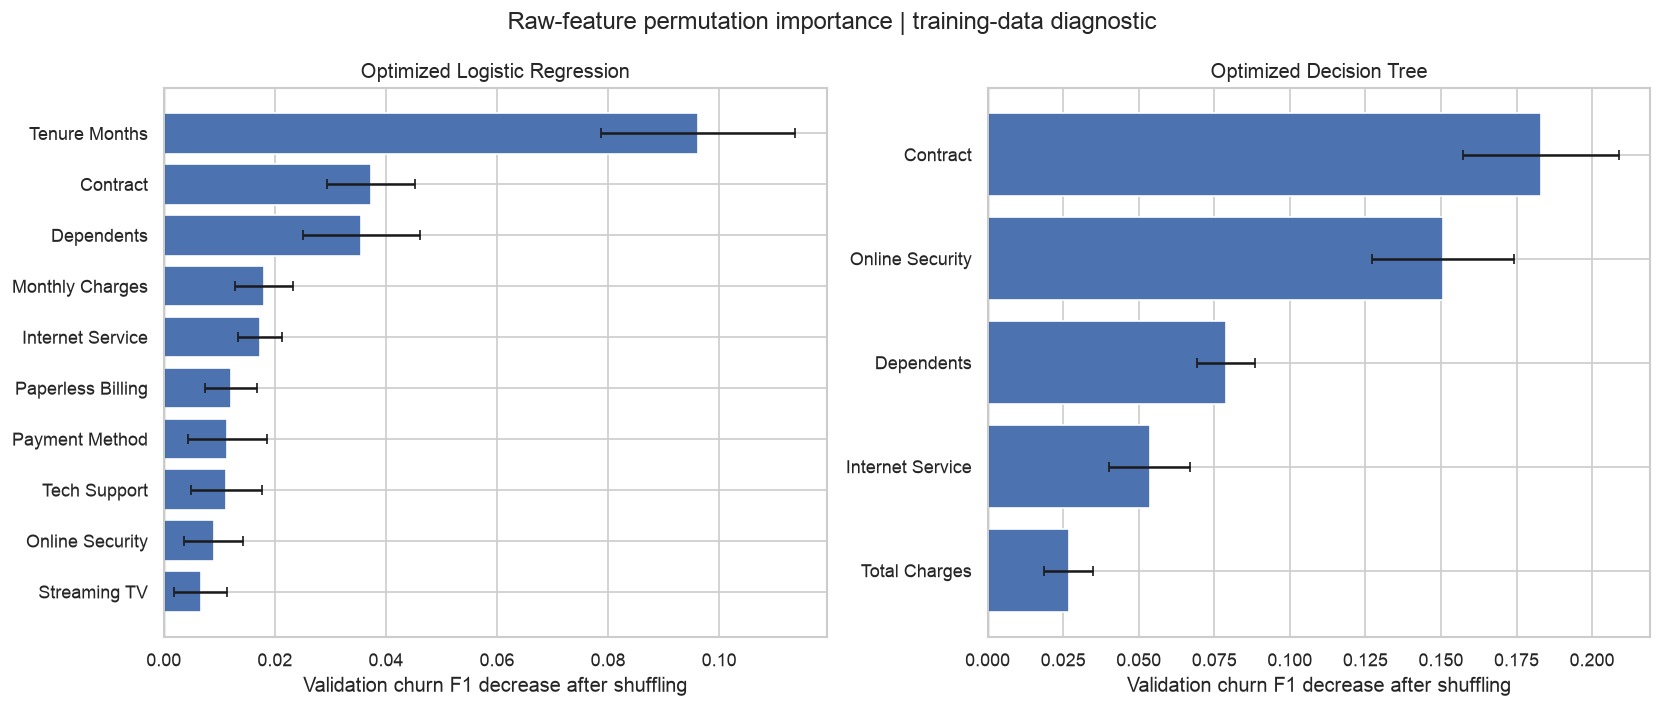

In [12]:
# Inspect LR coefficients and tree rules, then measure original-feature importance on a training holdout.
from sklearn.base import clone
from sklearn.inspection import permutation_importance

linear_pipeline = models["Optimized Logistic Regression"]
linear_features = linear_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = pd.Series(linear_pipeline.named_steps["model"].coef_[0],
                         index=linear_features, name="Coefficient")
print("Largest absolute encoded coefficients; do not compare numeric and categorical magnitudes directly:")
display(coefficients.loc[coefficients.abs().sort_values(ascending=False).head(15).index].to_frame().round(4))
scaler = linear_pipeline.named_steps["preprocessor"].named_transformers_["numeric"].named_steps["scaler"]
numeric_effects = pd.DataFrame({"Input": numeric_columns,
    "Training scale (one SD)": scaler.scale_,
    "Log-odds per SD": [coefficients[f"numeric__{c}"] for c in numeric_columns]})
numeric_effects["Odds multiplier per SD"] = np.exp(numeric_effects["Log-odds per SD"])
display(numeric_effects.set_index("Input").round(4))

contrast_rows = []
for field, a, b in [("Contract", "Month-to-month", "Two year"),
                     ("Contract", "Month-to-month", "One year"),
                     ("Dependents", "Yes", "No"),
                     ("Internet Service", "Fiber optic", "DSL")]:
    difference = coefficients[f"categorical__{field}_{a}"] - coefficients[f"categorical__{field}_{b}"]
    contrast_rows.append({"Comparison holding other inputs fixed": f"{field}: {a} versus {b}",
                          "Log-odds contrast": difference, "Model-implied odds ratio": np.exp(difference)})
display(pd.DataFrame(contrast_rows).set_index("Comparison holding other inputs fixed").round(4))
print("These conditional, regularized associations have no causal interpretation or coefficient uncertainty intervals.")

tree_pipeline = models["Optimized Decision Tree"]
tree_features = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(tree_pipeline.named_steps["model"].feature_importances_,
                       index=tree_features, name="Impurity importance").sort_values(ascending=False)
display(importance.head(15).to_frame().round(4))
print("Fitted tree depth:", tree_pipeline.named_steps["model"].get_depth(),
      "| leaves:", tree_pipeline.named_steps["model"].get_n_leaves())
tree_display_names = [name.replace("categorical__", "").replace("numeric__", "") for name in tree_features]
plt.figure(figsize=(17, 8))
plot_tree(tree_pipeline.named_steps["model"], feature_names=tree_display_names,
          class_names=["No churn", "Churn"], filled=True, max_depth=2,
          fontsize=10, rounded=True, impurity=False)
plt.title("Optimized Decision Tree | first three levels; deeper branches hidden")
plt.tight_layout()
plt.show()

# Interpret on a held-out portion of the original training data, not the reused test.
# Configurations were tuned on the full training set, so this is exploratory attribution.
interpret_fit_X, interpret_valid_X, interpret_fit_y, interpret_valid_y = train_test_split(
    X_train, y_train, test_size=.25, stratify=y_train, random_state=73)
permutation_tables = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["Optimized Logistic Regression", "Optimized Decision Tree"]):
    interpret_model = clone(models[name]).fit(interpret_fit_X, interpret_fit_y)
    permutation = permutation_importance(interpret_model, interpret_valid_X, interpret_valid_y,
        scoring=threshold_f1 if name == "Optimized Logistic Regression" else "f1", n_repeats=8, random_state=RANDOM_STATE, n_jobs=1)
    table = pd.DataFrame({"Mean F1 decrease": permutation.importances_mean,
                          "Permutation SD": permutation.importances_std}, index=X_train.columns)
    permutation_tables[name] = table.sort_values("Mean F1 decrease", ascending=False)
    print(name, "| diagnostic validation F1:", round(f1_score(interpret_valid_y, predict_at_threshold(interpret_model, interpret_valid_X, LR_THRESHOLD if name == "Optimized Logistic Regression" else .5)), 4))
    display(permutation_tables[name].round(4))
    top = permutation_tables[name].query("`Mean F1 decrease` > 0").head(10).sort_values("Mean F1 decrease")
    ax.barh(top.index, top["Mean F1 decrease"], xerr=top["Permutation SD"], capsize=3)
    ax.axvline(0, color="black", linewidth=.7)
    ax.set(title=name, xlabel="Validation churn F1 decrease after shuffling")
fig.suptitle("Raw-feature permutation importance | training-data diagnostic")
plt.tight_layout()
plt.show()
print("A raw column is shuffled before pipeline encoding, so all its one-hot levels are assessed together. "
      "Error bars show permutation-repeat SD, not confidence intervals. Correlated inputs can substitute "
      "for one another; shuffling can create unrealistic combinations. These are refitted diagnostic models.")


In [13]:
# Interpret the calculated feature rankings and distinguish conditional coefficients from marginal correlations.
from IPython.display import Markdown
top_lr = ", ".join(permutation_tables["Optimized Logistic Regression"].head(3).index)
top_tree = ", ".join(permutation_tables["Optimized Decision Tree"].head(3).index)
total_coef = coefficients["numeric__Total Charges"]
total_corr = corr.loc["Total Charges", "Churn"]
display(Markdown(f"""
### Interpretation findings

In the training-validation permutation diagnostic, the three largest raw-field F1 decreases are **{top_lr}** for optimized LR and **{top_tree}** for the optimized tree. Read the full tables, including negative and near-zero values: a small decrease means limited incremental reliance in this diagnostic, not that a feature has no business relevance. Rankings depend on the fitted sample and F1 scoring.

**Total Charges illustrates conditional versus marginal interpretation:** its training churn correlation is **{total_corr:.4f}**, while its optimized LR standardized coefficient is **{total_coef:.4f}**. The coefficient holds tenure and other encoded inputs fixed. Strong tenure/charges correlation and regularization complicate attribution; neither quantity estimates the effect of changing a customer's bill.

The coefficient contrasts, visible tree rules and permutation diagnostics explain different aspects of the models. Agreement strengthens a descriptive interpretation; disagreement calls for stability checks and consideration of correlated inputs. None identifies customers whose churn would be prevented by an offer.
"""))





### Interpretation findings

In the training-validation permutation diagnostic, the three largest raw-field F1 decreases are **Tenure Months, Contract, Dependents** for optimized LR and **Contract, Online Security, Dependents** for the optimized tree. Read the full tables, including negative and near-zero values: a small decrease means limited incremental reliance in this diagnostic, not that a feature has no business relevance. Rankings depend on the fitted sample and F1 scoring.

**Total Charges illustrates conditional versus marginal interpretation:** its training churn correlation is **-0.1948**, while its optimized LR standardized coefficient is **-0.1007**. The coefficient holds tenure and other encoded inputs fixed. Strong tenure/charges correlation and regularization complicate attribution; neither quantity estimates the effect of changing a customer's bill.

The coefficient contrasts, visible tree rules and permutation diagnostics explain different aspects of the models. Agreement strengthens a descriptive interpretation; disagreement calls for stability checks and consideration of correlated inputs. None identifies customers whose churn would be prevented by an offer.


### Controlled Comparison of ZIP Code and Cutoff

LR is held at C=0.1 with balanced weights across four scenarios. Identical customers and folds isolate the effects of ZIP removal and the 0.50-to-0.60 cutoff change. These fixed-setting results are separate from the final search, which selects C=0.01 using training CV.


In [14]:
# Hold LR settings fixed to compare ZIP inclusion and cutoffs 0.50 and 0.60 on identical customers.
from sklearn.base import clone

# Controlled comparison holds C and class weights fixed across all four cases.
# Both feature sets use identical customers and folds; no choices are made from test scores.
zip_column = clean.loc[X_train.index.union(X_test.index), "Zip Code"].map(
    lambda value: f"{int(value):05d}" if pd.notna(value) else np.nan)
ablation_rows = []
for include_zip in (True, False):
    train_features, test_features = X_train.copy(), X_test.copy()
    preprocessor = make_preprocessor()
    if include_zip:
        train_features["Zip Code"] = zip_column.loc[train_features.index]
        test_features["Zip Code"] = zip_column.loc[test_features.index]
        transformer = preprocessor.transformers[1]
        preprocessor.transformers[1] = (transformer[0], transformer[1], categorical_columns + ["Zip Code"])
    controlled = Pipeline([("preprocessor", preprocessor),
                           ("model", LogisticRegression(C=.1, class_weight="balanced",
                                                        max_iter=3000, random_state=RANDOM_STATE))])
    oof = cross_val_predict(controlled, train_features, y_train, cv=CV,
                           method="predict_proba", n_jobs=1)[:, 1]
    controlled.fit(train_features, y_train)
    probabilities = controlled.predict_proba(test_features)[:, list(controlled.classes_).index(1)]
    for threshold in (.50, .60):
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0,1]).ravel()
        ablation_rows.append({"ZIP included": include_zip, "Threshold": threshold,
            "Training OOF F1": f1_score(y_train, oof >= threshold),
            "Test Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions), "TP": int(tp), "FN": int(fn),
            "FP": int(fp), "TN": int(tn)})
ablation_table = pd.DataFrame(ablation_rows)
display(ablation_table.round(4))
print("C=0.1 and balanced weights are frozen for this controlled comparison; final search results are reported separately.")


C=0.1 and balanced weights are frozen for this controlled comparison; final search results are reported separately.


,ZIP included,Threshold,Training OOF F1,Test Accuracy,Precision,Recall,F1,TP,FN,FP,TN
0,True,0.5,0.6431,0.7480,0.5172,0.7647,0.6170,286,88,267,768
1,True,0.6,0.6489,0.7800,0.5681,0.7139,0.6327,267,107,203,832
2,False,0.5,0.6427,0.7445,0.5124,0.7727,0.6162,289,85,275,760
3,False,0.6,0.6510,0.7793,0.5663,0.7193,0.6337,269,105,206,829


## 8 Discussion and Conclusion

Optimized LR is selected by mean training CV F1 of 0.6512, with C=0.01, balanced weights and cutoff 0.60. Its test F1 is 0.6277, accuracy 77.86%, precision 56.68% and recall 70.32%. Compared with the previous ZIP-based configuration at cutoff 0.50, it produces fewer false alerts and misses more churners.

The controlled comparison shows a small incremental ZIP effect. Removal simplifies the input representation. The paired LR-versus-tree F1 interval includes zero, so the observed advantage remains uncertain. Independent validation, calibrated risks, verified input timing and intervention costs are required before business use.


## 9 Model Export and API

The selected fitted pipeline is wrapped in FixedThresholdClassifier with FrozenEstimator to preserve its fitted parameters and apply cutoff 0.60. The export includes the classifier, 19-field schema, decision threshold and example request.

Run python3 api/server.py from the project directory. The API uses the exported decision rule and accepts the fields in models/example_request.json.


In [15]:
# Export the fitted candidate, its fixed cutoff, input schema, and example request for API inference.
import json
import platform
import joblib

export_dir = Path("models")
export_dir.mkdir(exist_ok=True)
from sklearn.frozen import FrozenEstimator
selected_threshold = LR_THRESHOLD if recommended_name == "Optimized Logistic Regression" else 0.50
selected_pipeline = FixedThresholdClassifier(
    FrozenEstimator(models[recommended_name]), threshold=selected_threshold,
    response_method="predict_proba").fit(X_train, y_train)
fields = []
for name in X_train.columns:
    field = {"name": name, "type": "number" if name in numeric_columns else "string"}
    if name not in numeric_columns:
        field["categories"] = sorted(X_train[name].dropna().astype(str).unique().tolist())
    fields.append(field)
example = json.loads(X_train.iloc[0].to_json())
artifact = {
    "artifact_version": 1,
    "model_name": recommended_name,
    "decision_threshold": selected_threshold,
    "pipeline": selected_pipeline,
    "fields": fields,
    "example": example,
    "excluded_columns": excluded,
    "target": TARGET_COLUMN,
    "versions": {"python": platform.python_version(), "pandas": pd.__version__,
                 "numpy": np.__version__, "scikit-learn": sklearn.__version__,
                 "joblib": joblib.__version__},
}
joblib.dump(artifact, export_dir / "churn_pipeline.joblib")
(export_dir / "schema.json").write_text(json.dumps(
    {k: v for k, v in artifact.items() if k != "pipeline"}, indent=2, ensure_ascii=False) + "\n")
(export_dir / "example_request.json").write_text(
    json.dumps({"customer": example}, indent=2, ensure_ascii=False) + "\n")
print("Exported:", artifact["model_name"])
print("Predictor count:", len(fields))
print("Start the API: python3 api/server.py")


Exported: Optimized Logistic Regression
Predictor count: 19
Start the API: python3 api/server.py


## References

- scikit-learn. Common pitfalls and recommended practices. https://scikit-learn.org/stable/common_pitfalls.html
- scikit-learn. LogisticRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- scikit-learn. DecisionTreeClassifier. https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn. GridSearchCV. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- scikit-learn. FixedThresholdClassifier. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.FixedThresholdClassifier.html
